# E-commerce Customer Segmentation: RFM + Cohort Retention (Online Retail II)

**Business question:** which customers drive revenue, who is about to churn, and where should a retention budget go?

This notebook works through the analysis an e-commerce or marketplace analyst would hand to a growth or CRM team:

1. **Data cleaning**: cancellations, returns, missing customer IDs, non-product lines
2. **Business KPIs**: revenue, orders, AOV, active customers, monthly trend
3. **Pareto check**: how concentrated is revenue?
4. **RFM segmentation**: Recency, Frequency, Monetary scores mapped to action-ready segments
5. **Cohort retention**: how many customers come back after their first purchase month?
6. **Recommendations**: what to do with each segment

Dataset: [Online Retail II (UCI)](https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci), about 1M transaction lines from a UK online gift retailer, Dec 2009 to Dec 2011.

> **TL;DR**
> 1. The top 20% of customers bring in 77% of revenue (Online Retail II, a UK online gift retailer, 2009-2011).
> 2. Champions + Loyal Customers are 34% of customers but 79% of revenue; At Risk + Can't Lose Them are 14% of customers holding 9% of past revenue.
> 3. Only about 19% of new customers buy again the next month, so the second order is the biggest leak to fix.

In [1]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

def find_file(name):
    """Locate a dataset file wherever Kaggle mounts it under /kaggle/input."""
    for root in ["/kaggle/input", "../input", "data", "/workspace/kaggle/data"]:
        hits = glob.glob(os.path.join(root, "**", name), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(name)

path = find_file("online_retail_II.csv")
raw = pd.read_csv(path, dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns")
raw.head()

Loaded 1,067,371 rows x 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 1. Data quality and cleaning
Rules (standard for this dataset):
- Invoices starting with **"C"** are cancellations. They are tracked separately as a return-rate KPI, not counted as sales.
- Rows with **no Customer ID** cannot be segmented, so they are excluded from customer analysis (but reported).
- **Non-product stock codes** (postage, bank charges, manual adjustments) are removed.
- Exact **duplicate lines** and non-positive quantity/price rows are dropped.

In [2]:
dq = pd.Series({
    "rows": len(raw),
    "missing Customer ID": raw["Customer ID"].isna().sum(),
    "cancellation lines": raw["Invoice"].str.startswith("C").sum(),
    "duplicate lines": raw.duplicated().sum(),
    "non-positive price": (raw["Price"] <= 0).sum(),
})
display(dq.to_frame("count").assign(pct=lambda d: (d["count"] / len(raw) * 100).round(2)))

non_product = {"POST", "DOT", "M", "C2", "BANK CHARGES", "AMAZONFEE", "D", "S", "B", "CRUK", "PADS", "ADJUST", "ADJUST2", "TEST001", "TEST002"}
df = raw.drop_duplicates()
cancels = df[df["Invoice"].str.startswith("C")]
df = df[~df["Invoice"].str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["Price"] > 0) & (~df["StockCode"].str.upper().isin(non_product))].copy()
df["Revenue"] = df["Quantity"] * df["Price"]
df["Month"] = df["InvoiceDate"].dt.to_period("M")

cust = df.dropna(subset=["Customer ID"]).copy()
cust["Customer ID"] = cust["Customer ID"].astype(int)
print(f"Clean sales lines: {len(df):,} | with customer ID: {len(cust):,}")
print(f"Revenue not attributable to a known customer: {1 - cust.Revenue.sum() / df.Revenue.sum():.1%}")

,count,pct
rows,1067371,100.00
missing Customer ID,243007,22.77
cancellation lines,19494,1.83
duplicate lines,34335,3.22
non-positive price,6207,0.58


Clean sales lines: 1,003,417 | with customer ID: 776,579
Revenue not attributable to a known customer: 13.1%


## 2. Business KPIs

In [3]:
kpi = pd.DataFrame([
    ("Net revenue (GBP)", f"{df['Revenue'].sum():,.0f}"),
    ("Orders", f"{df['Invoice'].nunique():,}"),
    ("Identified customers", f"{cust['Customer ID'].nunique():,}"),
    ("Average order value (GBP)", f"{df.groupby('Invoice')['Revenue'].sum().mean():,.2f}"),
    ("Orders per customer", f"{cust.groupby('Customer ID')['Invoice'].nunique().mean():.2f}"),
    ("Cancelled order share", f"{cancels['Invoice'].nunique() / (cancels['Invoice'].nunique() + df['Invoice'].nunique()):.1%}"),
], columns=["KPI", "Value"])
kpi

,KPI,Value
0,Net revenue (GBP),"19,645,618"
1,Orders,"39,516"
2,Identified customers,"5,852"
3,Average order value (GBP),497.16
4,Orders per customer,6.25
5,Cancelled order share,17.3%


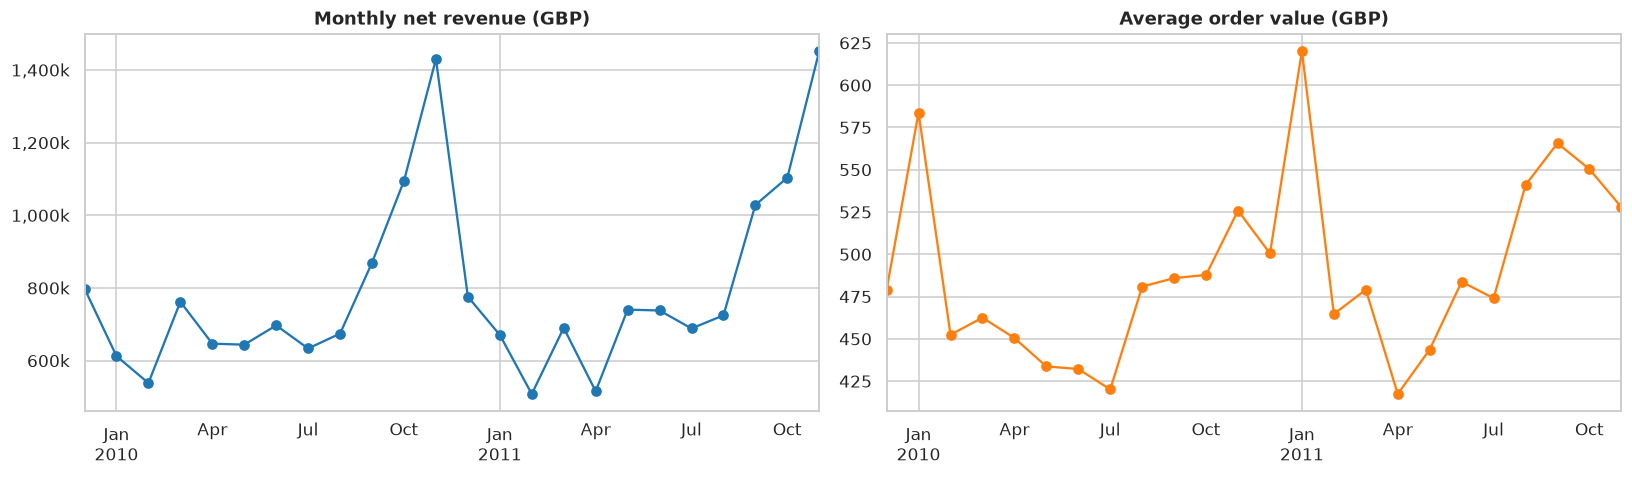

Dec 2011 is excluded from the trend because the data ends on 9 Dec 2011 (partial month).
Seasonality: the average November is 1.8x the average month (gift retailer, Q4 peak).


In [4]:
monthly = df[df["InvoiceDate"] < "2011-12-01"].groupby("Month").agg(
    revenue=("Revenue", "sum"), orders=("Invoice", "nunique"), customers=("Customer ID", "nunique"))
monthly["aov"] = monthly["revenue"] / monthly["orders"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
monthly["revenue"].plot(ax=axes[0], marker="o", color="#1f77b4")
axes[0].set_title("Monthly net revenue (GBP)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}k"))
monthly["aov"].plot(ax=axes[1], marker="o", color="#ff7f0e")
axes[1].set_title("Average order value (GBP)")
for a in axes: a.set_xlabel("")
plt.tight_layout(); plt.show()
print("Dec 2011 is excluded from the trend because the data ends on 9 Dec 2011 (partial month).")
nov = monthly["revenue"].groupby(monthly.index.month).mean()
print(f"Seasonality: the average November is {nov.loc[11] / nov.mean():.1f}x the average month (gift retailer, Q4 peak).")

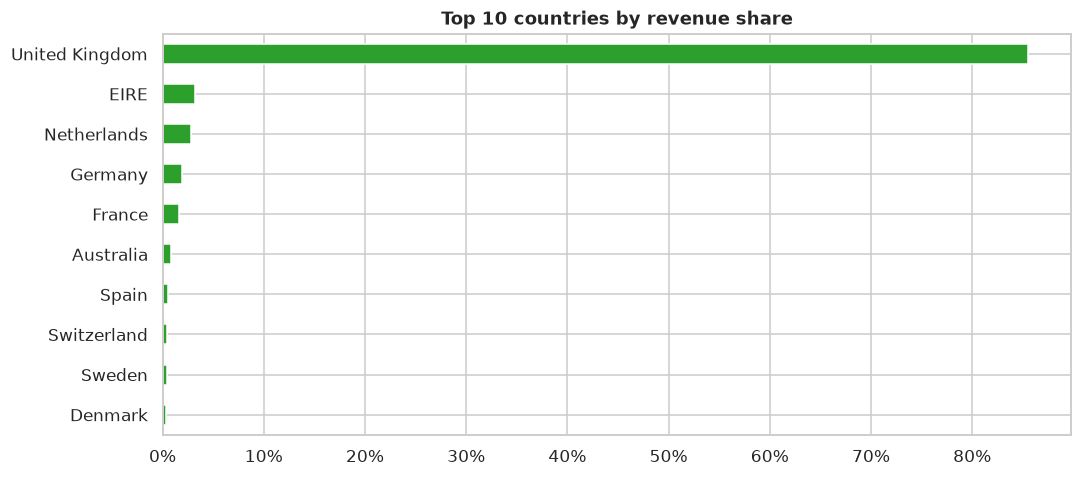

UK share of revenue: 85.5%; the next 9 countries add 12.1%


In [5]:
country = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
share = country / country.sum()
fig, ax = plt.subplots(figsize=(10, 4.5))
share.head(10)[::-1].plot.barh(ax=ax, color="#2ca02c")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_title("Top 10 countries by revenue share"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print(f"UK share of revenue: {share.get('United Kingdom', 0):.1%}; the next 9 countries add {share.iloc[1:10].sum():.1%}")

## 3. Pareto check: how concentrated is customer revenue?

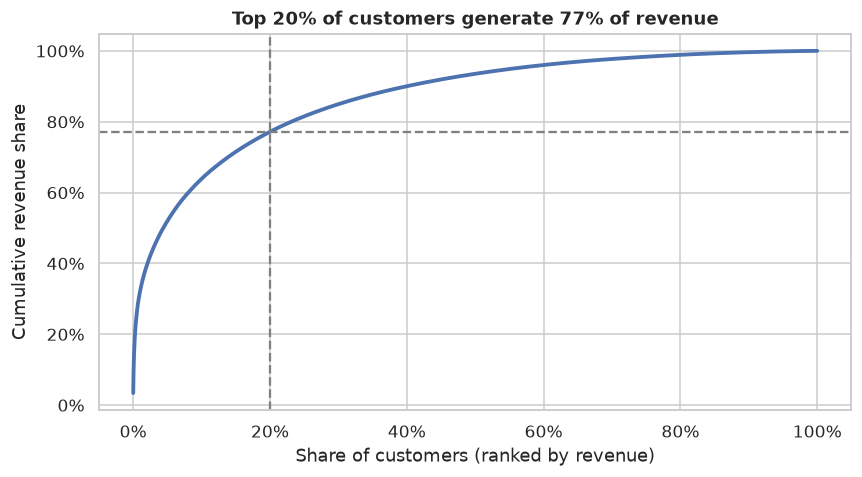

In [6]:
cust_rev = cust.groupby("Customer ID")["Revenue"].sum().sort_values(ascending=False)
cum = cust_rev.cumsum() / cust_rev.sum()
x = np.arange(1, len(cum) + 1) / len(cum)
top20 = cum.iloc[int(len(cum) * 0.2) - 1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, cum.values, lw=2.5)
ax.axvline(0.2, ls="--", c="grey"); ax.axhline(top20, ls="--", c="grey")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title(f"Top 20% of customers generate {top20:.0%} of revenue")
ax.set_xlabel("Share of customers (ranked by revenue)"); ax.set_ylabel("Cumulative revenue share")
plt.tight_layout(); plt.show()

## 4. RFM segmentation
- **Recency**: days since last purchase (measured from the day after the last invoice in the data)
- **Frequency**: number of distinct orders
- **Monetary**: total net revenue

Each metric is scored 1 to 5 by quintile (5 = best). The R and F scores are mapped to the classic RFM segment grid, which turns the scores into actions a CRM team can run.

In [7]:
snapshot = cust["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = cust.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"))

rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

seg_map = {
    r"[1-2][1-2]": "Hibernating", r"[1-2][3-4]": "At Risk", r"[1-2]5": "Can't Lose Them",
    r"3[1-2]": "About to Sleep", r"33": "Need Attention", r"[3-4][4-5]": "Loyal Customers",
    r"41": "Promising", r"51": "New Customers", r"[4-5][2-3]": "Potential Loyalists", r"5[4-5]": "Champions",
}
rfm["Segment"] = (rfm["R"].astype(str) + rfm["F"].astype(str)).replace(seg_map, regex=True)
rfm.head()

,Recency,Frequency,Monetary,R,F,M,Segment
Customer ID,,,,,,,
12346,326,3,77352.96,2,3,5,At Risk
12347,2,8,4921.53,5,4,5,Champions
12348,75,5,1658.40,3,4,4,Loyal Customers
12349,19,3,3678.69,5,3,5,Potential Loyalists
12350,310,1,294.40,2,1,2,Hibernating


In [8]:
seg = rfm.groupby("Segment").agg(
    customers=("Recency", "size"), avg_recency_days=("Recency", "mean"),
    avg_orders=("Frequency", "mean"), avg_revenue=("Monetary", "mean"), revenue=("Monetary", "sum"))
seg["customer_share"] = seg["customers"] / seg["customers"].sum()
seg["revenue_share"] = seg["revenue"] / seg["revenue"].sum()
seg = seg.sort_values("revenue", ascending=False)
seg.style.format({"avg_recency_days": "{:.0f}", "avg_orders": "{:.1f}", "avg_revenue": "£{:,.0f}",
                  "revenue": "£{:,.0f}", "customer_share": "{:.1%}", "revenue_share": "{:.1%}"}) \
   .background_gradient(subset=["revenue_share"], cmap="Greens")

,customers,avg_recency_days,avg_orders,avg_revenue,revenue,customer_share,revenue_share
Segment,,,,,,,
Champions,834,9,19.2,"£10,541","£8,791,498",14.3%,51.5%
Loyal Customers,1149,67,9.8,"£4,050","£4,652,913",19.6%,27.3%
At Risk,757,372,3.9,"£1,442","£1,091,837",12.9%,6.4%
Potential Loyalists,714,26,2.6,"£1,141","£814,742",12.2%,4.8%
Hibernating,1508,457,1.2,£411,"£620,259",25.8%,3.6%
Can't Lose Them,71,329,16.3,"£7,059","£501,159",1.2%,2.9%
Need Attention,266,113,3.1,"£1,263","£336,023",4.5%,2.0%
About to Sleep,382,106,1.4,£526,"£200,996",6.5%,1.2%
Promising,116,39,1.0,£345,"£40,017",2.0%,0.2%


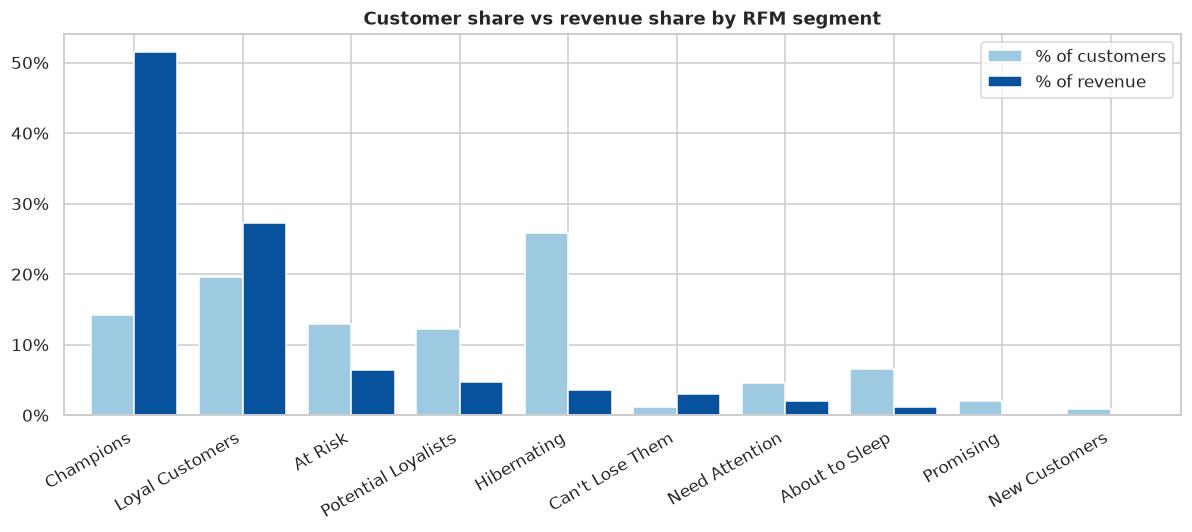

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
seg[["customer_share", "revenue_share"]].rename(columns={"customer_share": "% of customers", "revenue_share": "% of revenue"}) \
    .plot.bar(ax=ax, width=0.8, color=["#9ecae1", "#08519c"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_title("Customer share vs revenue share by RFM segment"); ax.set_xlabel("")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

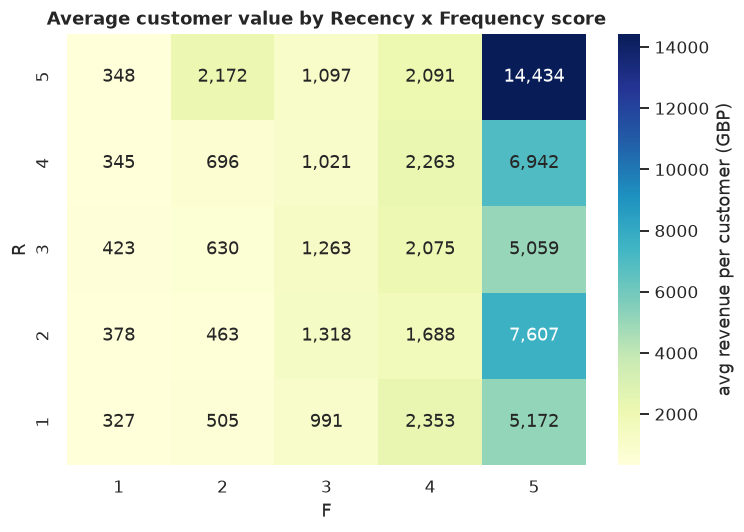

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
grid = rfm.pivot_table(index="R", columns="F", values="Monetary", aggfunc="mean").sort_index(ascending=False)
sns.heatmap(grid, annot=True, fmt=",.0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "avg revenue per customer (GBP)"})
ax.set_title("Average customer value by Recency x Frequency score")
plt.tight_layout(); plt.show()

## 5. Cohort retention
Customers are grouped by the month of their **first purchase**. Each cell shows the share of that cohort that bought again *n* months later.

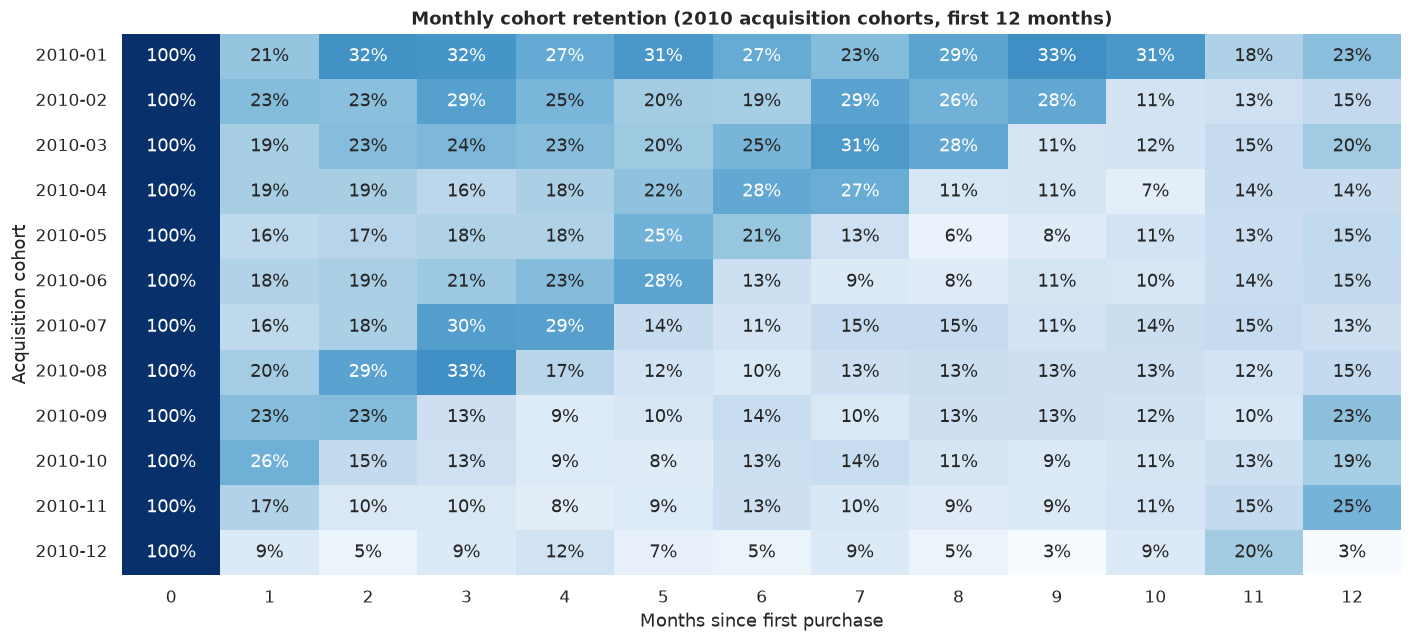

Average month-1 retention (2010-01 to 2011-06 cohorts): 19.4% | month-3: 20.4%


In [11]:
c = cust[["Customer ID", "InvoiceDate"]].copy()
c["order_month"] = c["InvoiceDate"].dt.to_period("M")
c["cohort"] = c.groupby("Customer ID")["order_month"].transform("min")
c["age"] = (c["order_month"].dt.year - c["cohort"].dt.year) * 12 + (c["order_month"].dt.month - c["cohort"].dt.month)
cohort = c.groupby(["cohort", "age"])["Customer ID"].nunique().unstack()
retention = cohort.divide(cohort[0], axis=0)
ret_show = retention.loc["2010-01":"2010-12", 0:12]

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(ret_show, annot=True, fmt=".0%", cmap="Blues", vmax=0.5, ax=ax, cbar=False)
ax.set_title("Monthly cohort retention (2010 acquisition cohorts, first 12 months)")
ax.set_xlabel("Months since first purchase"); ax.set_ylabel("Acquisition cohort")
plt.tight_layout(); plt.show()

m1 = retention[1].loc["2010-01":"2011-06"].mean(); m3 = retention[3].loc["2010-01":"2011-06"].mean()
print(f"Average month-1 retention (2010-01 to 2011-06 cohorts): {m1:.1%} | month-3: {m3:.1%}")

## 6. Summary and recommended actions

In [12]:
s, n = seg["revenue_share"], seg["customer_share"]
champ_loyal_n = n.get("Champions", 0) + n.get("Loyal Customers", 0)
champ_loyal_s = s.get("Champions", 0) + s.get("Loyal Customers", 0)
risk_n = n.get("At Risk", 0) + n.get("Can't Lose Them", 0)
risk_s = s.get("At Risk", 0) + s.get("Can't Lose Them", 0)
print(f"1. The top 20% of customers = {top20:.0%} of revenue. Keeping the top tier matters more than acquisition volume.")
print(f"2. Champions + Loyal Customers = {champ_loyal_n:.0%} of customers but {champ_loyal_s:.0%} of revenue.")
print(f"3. At Risk + Can't Lose Them = {risk_n:.0%} of customers who hold {risk_s:.0%} of historical revenue. They are the win-back priority.")
print(f"4. Only about {m1:.0%} of new customers buy again the next month. The second order is the biggest leak in the funnel.")

1. The top 20% of customers = 77% of revenue. Keeping the top tier matters more than acquisition volume.
2. Champions + Loyal Customers = 34% of customers but 79% of revenue.
3. At Risk + Can't Lose Them = 14% of customers who hold 9% of historical revenue. They are the win-back priority.
4. Only about 19% of new customers buy again the next month. The second order is the biggest leak in the funnel.


| Segment | What it means | Recommended action |
|---|---|---|
| **Champions** | Recent, frequent, high spend | VIP early access, referral program, no discounts needed |
| **Loyal Customers** | Frequent buyers | Bundles, cross-sell, loyalty tiers |
| **Potential Loyalists / New / Promising** | Recent, low frequency | Onboarding flow, 2nd-order incentive within 30 days |
| **At Risk / Can't Lose Them** | Used to buy often, gone quiet | Personal win-back offers, the highest retention ROI |
| **About to Sleep / Need Attention** | Fading engagement | Reminder emails, best-seller recommendations |
| **Hibernating** | Low, old activity | Low-cost reactivation only, or suppress to save budget |

**Next steps:** add margin data to rank segments by profit rather than revenue, test win-back offers against a holdout group, and re-score customers weekly so CRM lists stay fresh.

*If you found this useful, an upvote is appreciated. Feedback is welcome in the comments.*

---
**Shahzad Raza** · E-commerce & marketing data analyst · [GitHub](https://github.com/Shahzrazaa) · [LinkedIn](https://www.linkedin.com/in/shahzadrazaa/)

📋 Free Amazon listing health checklist: https://adsmithai.gumroad.com/l/rxzumn

More notebooks: https://www.kaggle.com/shahzadrazaa/code